<a href="https://colab.research.google.com/github/sobitzy/gci-competition/blob/main/tutorial_adding_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# In-class Competition Tutorial
Following tutorial.ipynb, this notebook extends the baseline with feature addition, resulting in a minor but consistent increase in ROC-AUC.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [2]:
# Loading libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [4]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIWorld` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIWorld/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [5]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/GCI Global Competition/Competition"

/content/drive/MyDrive/GCI Global Competition/Competition


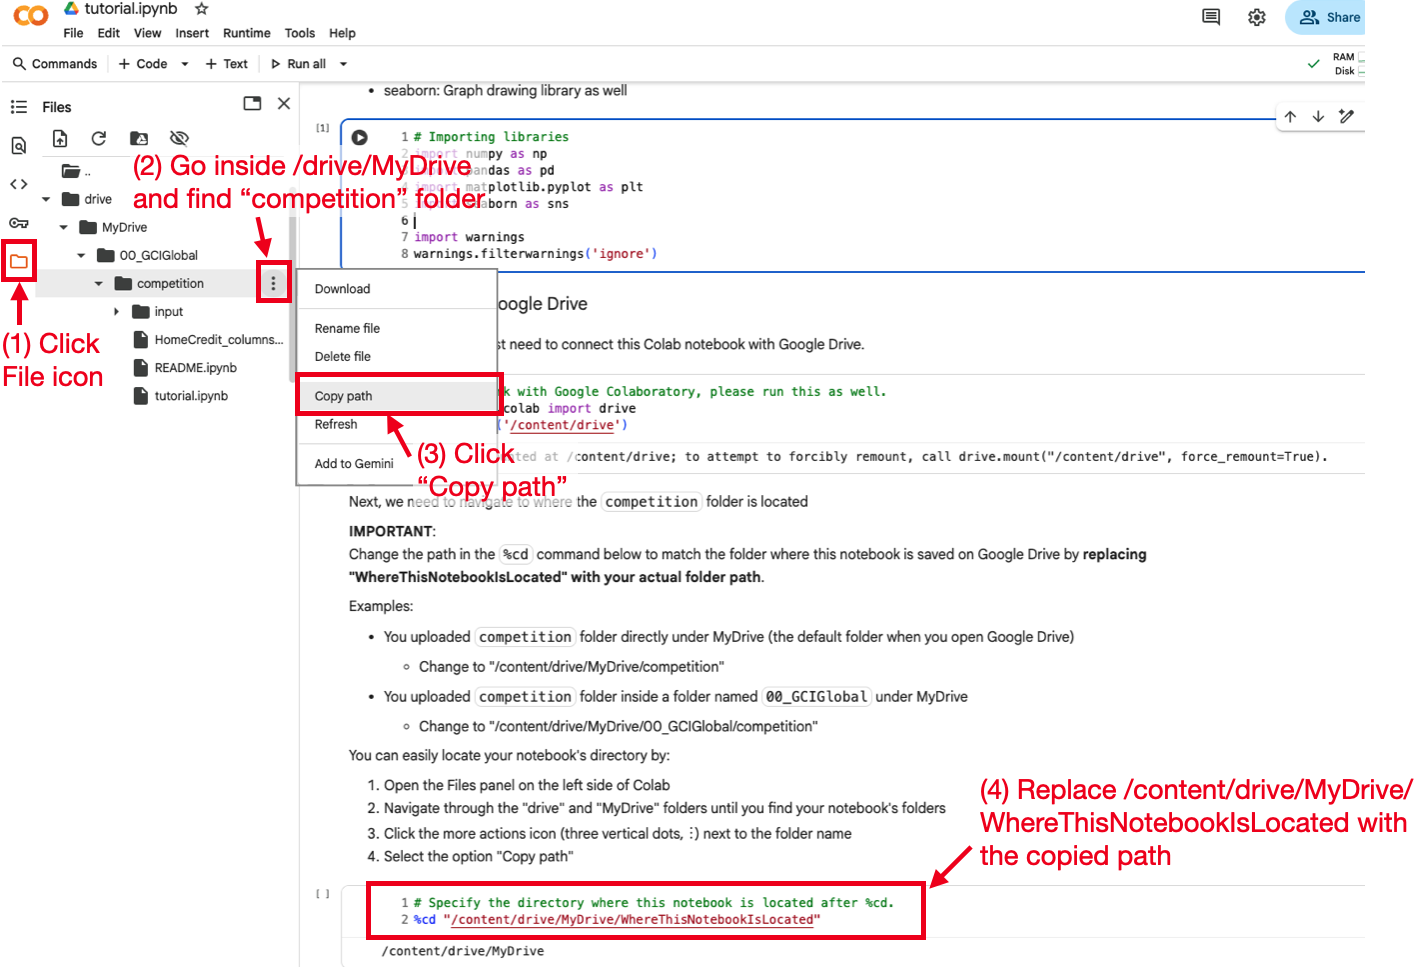

Run the cell below to check if the path is correctly set.

In [1]:
train_raw = pd.read_csv(train_file)
test_raw = pd.read_csv(test_file)

def make_features(df):
    X = df.drop(
        columns=["TARGET", "SK_ID_CURR"],
        errors="ignore",
    ).copy()

    # Keep missingness visible instead of replacing it with zero


    numeric_cols = X.select_dtypes(include="number").columns
    X["NUMERIC_MISSING_COUNT"] = X[numeric_cols].isna().sum(axis=1)

    ratios = {
        "CREDIT_INCOME_RATIO": ("AMT_CREDIT", "AMT_INCOME_TOTAL"),
        "ANNUITY_INCOME_RATIO": ("AMT_ANNUITY", "AMT_INCOME_TOTAL"),
        "CREDIT_ANNUITY_RATIO": ("AMT_CREDIT", "AMT_ANNUITY"),
        "CREDIT_GOODS_RATIO": ("AMT_CREDIT", "AMT_GOODS_PRICE"),
        "INCOME_PER_PERSON": ("AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"),
    }

    for name, (numerator, denominator) in ratios.items():
        if numerator in X.columns and denominator in X.columns:
            X[name] = X[numerator] / X[denominator].replace(0, np.nan)

    ext = [
        c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
        if c in X.columns
    ]

    if ext:
        X["EXT_MISSING_COUNT"] = X[ext].isna().sum(axis=1)

    if len(ext) >= 2:
        X["EXT_MEAN"] = X[ext].mean(axis=1)
        X["EXT_MIN"] = X[ext].min(axis=1)
        X["EXT_MAX"] = X[ext].max(axis=1)
        X["EXT_STD"] = X[ext].std(axis=1)

    missing_cols = [
        "OWN_CAR_AGE",
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3",
        "AMT_REQ_CREDIT_BUREAU_YEAR",
    ]

    for col in missing_cols:
      if col in X.columns:
        X[f"{col}_MISSING"] = X[col].isna().astype("int8")

    if "DAYS_EMPLOYED" in X.columns:
      X["EMPLOYED_ANOMALY"] = (
        X["DAYS_EMPLOYED"] == 365243
      ).astype("int8")

      X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].replace(365243, np.nan)


    def safe_ratio(a,b):
      return a / b.replace(0, np.nan)

    if {"DAYS_EMPLOYED", "DAYS_BIRTH"}.issubset(X.columns):
      age_days = -X["DAYS_BIRTH"]
      employed_days = -X["DAYS_EMPLOYED"]

      X["EMPLOYED_AGE_RATIO"] = safe_ratio(
          employed_days,
          age_days
          )

    if {"AMT_CREDIT", "AMT_GOODS_PRICE"}.issubset(X.columns):
        X["CREDIT_GOODS_DIFF"] = (X["AMT_CREDIT"] - X["AMT_GOODS_PRICE"])

    if {"AMT_ANNUITY", "AMT_GOODS_PRICE"}.issubset(X.columns):
        X["ANNUITY_GOODS_RATIO"] = safe_ratio(X["AMT_ANNUITY"], X["AMT_GOODS_PRICE"])

    from itertools import combinations

    ext_cols = [
        col for col in[
            "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"
        ]
        if col in X_columns
    ]

    for a, b in combinations(ext_cols, 2):
      X[f"{a}_X_{b}"] = X[a] * X[b]
      X[f"{a}_DIFF_{b}"] = X[a] - X[b]


    return X.replace([np.inf, -np.inf], np.nan)



X = make_features(train_raw)
X_test_new = make_features(test_raw)
y = train_raw["TARGET"]

assert X.columns.equals(X_test_new.columns)

print("Features:", X.shape[1])
print(X.columns.tolist())

NameError: name 'pd' is not defined

In [83]:
from sklearn.model_selection import train_test_split

X_train_new, X_valid_new, y_train_new, y_valid_new = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=0,
)

X_train_new = X_train_new.copy()
X_valid_new = X_valid_new.copy()
X_test_new = X_test_new.copy()

cat_cols = X_train_new.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Learn the category vocabulary from the training partition only.
for col in cat_cols:
    categories = (
        X_train_new[col]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    for frame in [X_train_new, X_valid_new, X_test_new]:
        frame[col] = pd.Categorical(
            frame[col].astype("string"),
            categories=categories,
        )

print("Categorical features:", cat_cols)


Categorical features: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']


In [108]:
from lightgbm import (
    LGBMClassifier,
    early_stopping,
    log_evaluation,
)
from sklearn.metrics import roc_auc_score

lgb_new = LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=4000,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.9,
    reg_alpha=0.1,
    reg_lambda=5.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

lgb_new.fit(
    X_train_new,
    y_train_new,
    categorical_feature=cat_cols,
    eval_set=[(X_valid_new, y_valid_new)],
    eval_metric="auc",
    callbacks=[
        early_stopping(
            stopping_rounds=100,
            first_metric_only=True,
        ),
        log_evaluation(period=100),
    ],
)

new_valid_pred = lgb_new.predict_proba(X_valid_new)[:, 1]

print(
    "New validation AUC:",
    roc_auc_score(y_valid_new, new_valid_pred),
)
print("Best boosting round:", lgb_new.best_iteration_)


Training until validation scores don't improve for 300 rounds
[100]	valid_0's auc: 0.744776
[200]	valid_0's auc: 0.752295
[300]	valid_0's auc: 0.754768
[400]	valid_0's auc: 0.755927
[500]	valid_0's auc: 0.756592
[600]	valid_0's auc: 0.756925
[700]	valid_0's auc: 0.757128
[800]	valid_0's auc: 0.75732
[900]	valid_0's auc: 0.757154
[1000]	valid_0's auc: 0.756913
[1100]	valid_0's auc: 0.756801
Early stopping, best iteration is:
[802]	valid_0's auc: 0.757329
Evaluated only: auc
New validation AUC: 0.7573288769098712
Best boosting round: 802


In [4]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [5]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [6]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [7]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

###This time, we'll review all candidate features and use the majority in our model.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [8]:
# Check missing values of train data
train.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


In [9]:
# Check missing values of test data
test.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


We found that there are missing values in OWN_CAR_AGE, CNT_FAM_MEMBERS, EXT_SOURCE_\*, AMT_REQ_CREDIT_BUREAU_\*. We will deal with these missing values later.

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

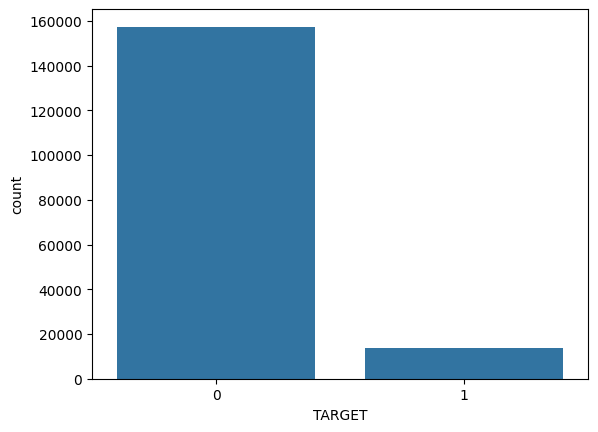

In [10]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

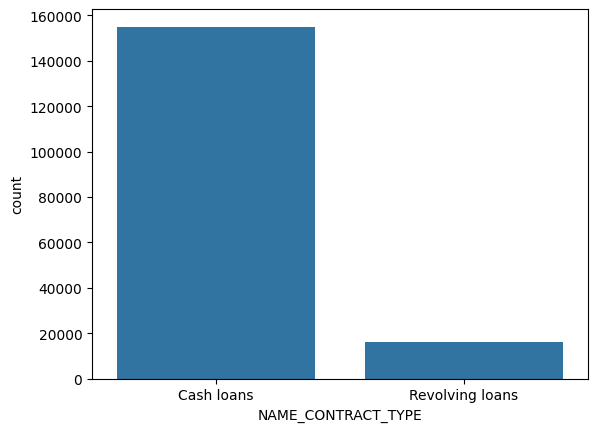

In [11]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in NAME_CONTRACT_TYPE, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

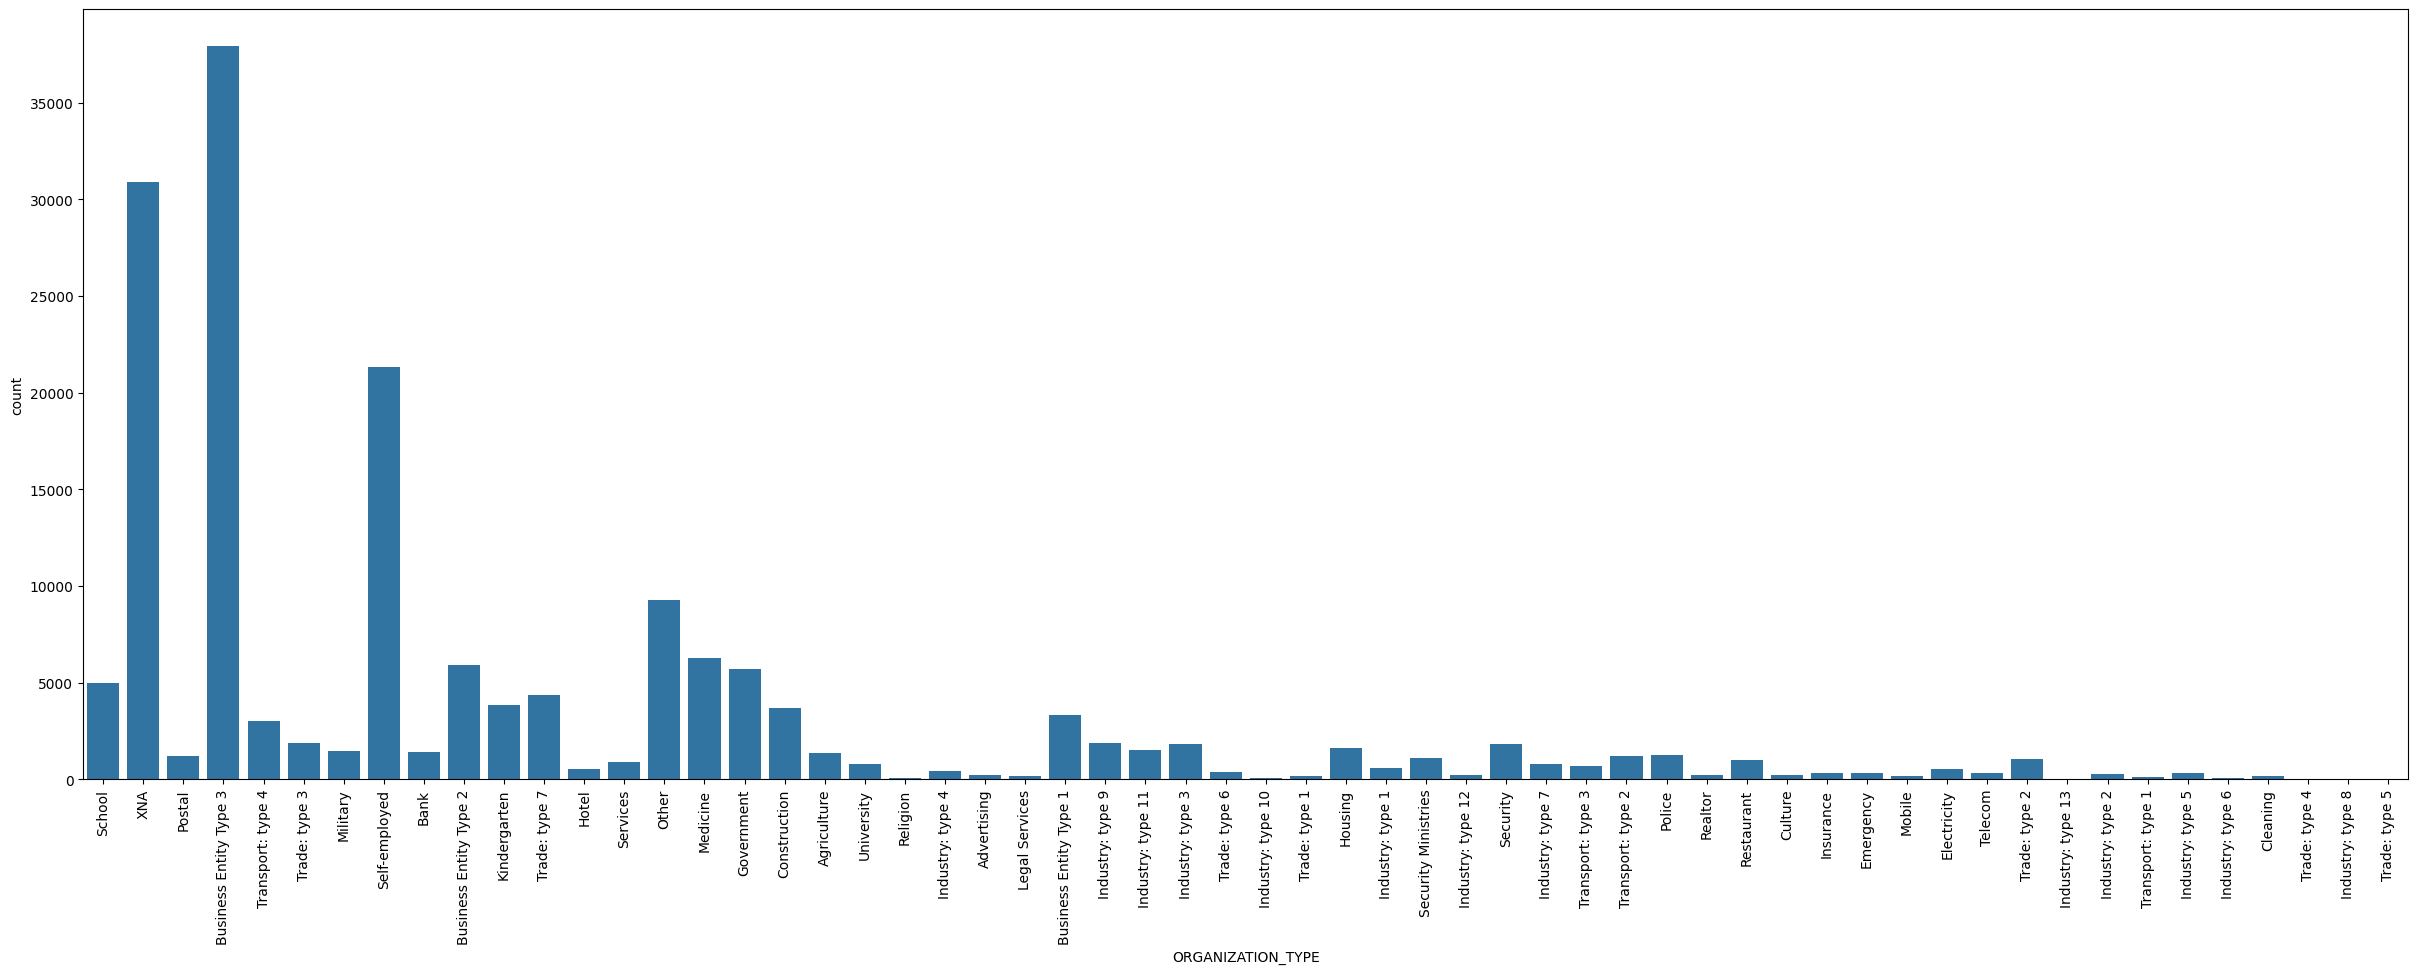

In [12]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

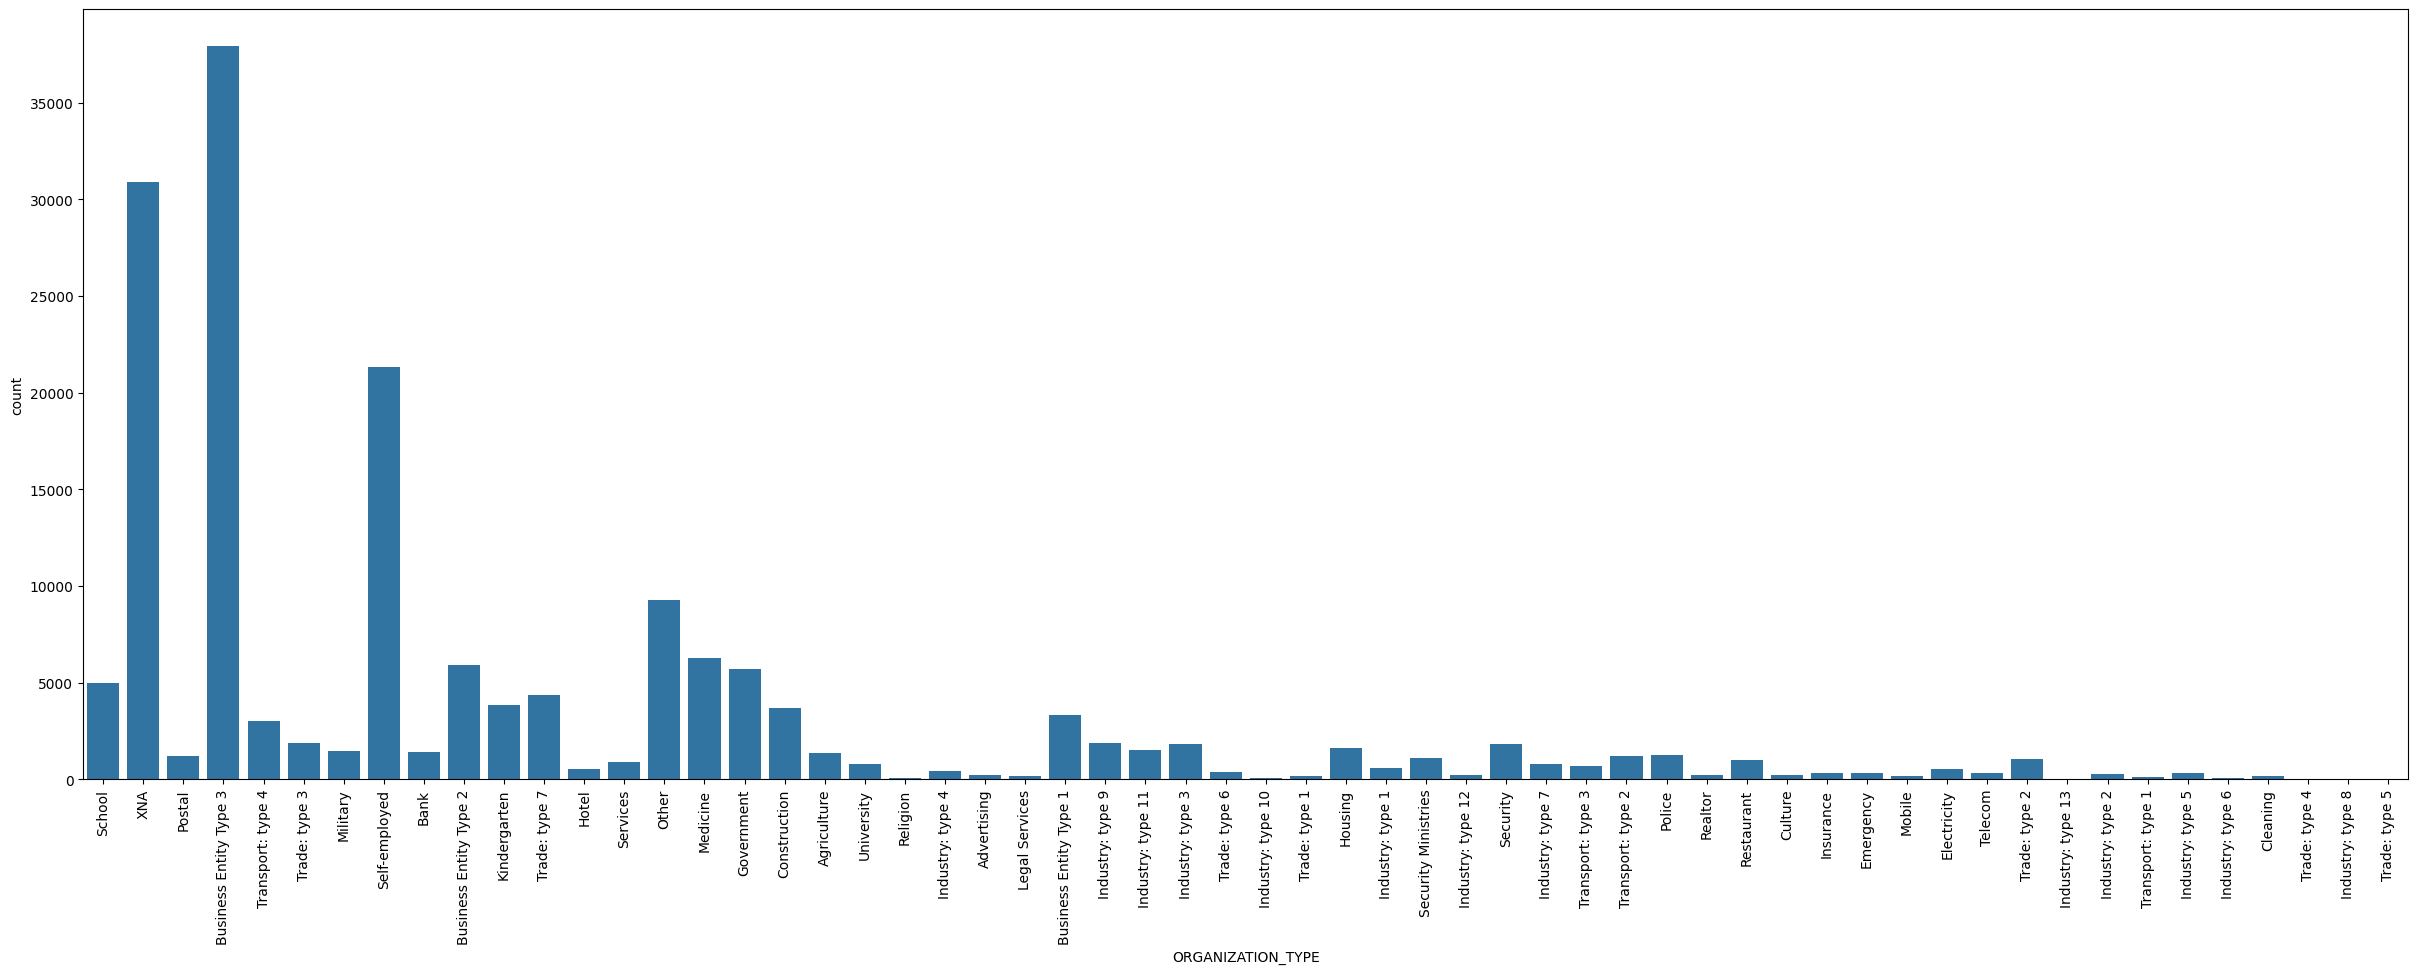

In [13]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different ORGANIZATION_TYPEs, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is “XNA,” which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_1 column

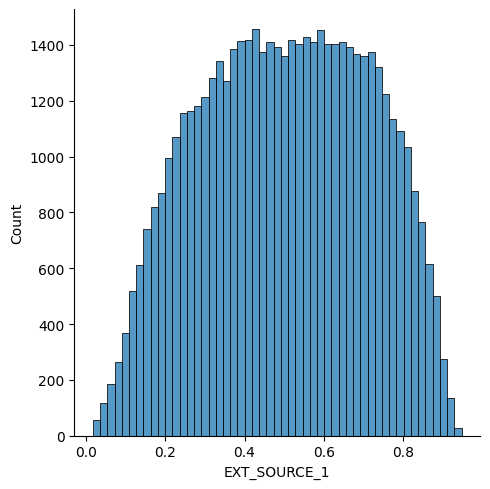

In [14]:
# The distribution of EXT_SOURCE_1
sns.displot(data=train, x="EXT_SOURCE_1")
plt.show()

#### EXT_SOURCE_2 column

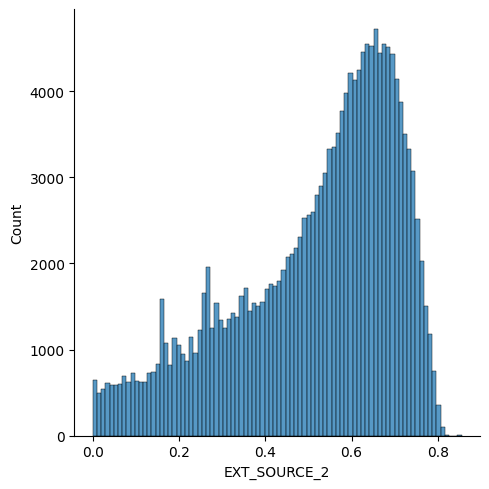

In [16]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

#### EXT_SOURCE_3 column

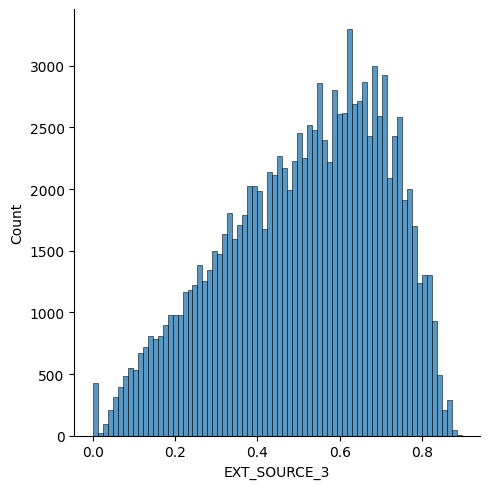

In [15]:
# The distribution of EXT_SOURCE_3
sns.displot(data=train, x="EXT_SOURCE_3")
plt.show()

We can see that EXT_SOURCE_\* is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL

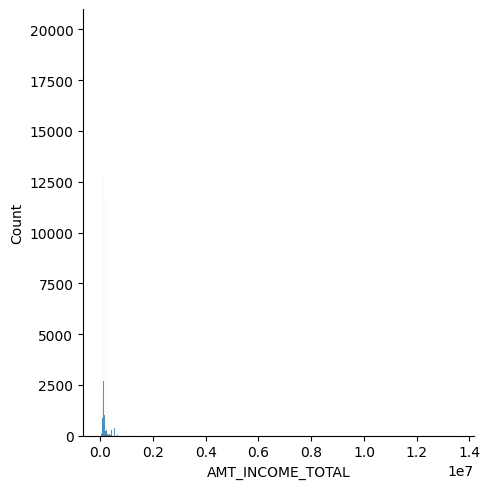

In [17]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret because the distribution is right-skewed with a small number of very large outliers. To visualize data like this, a logarithmic transformation can be effective.

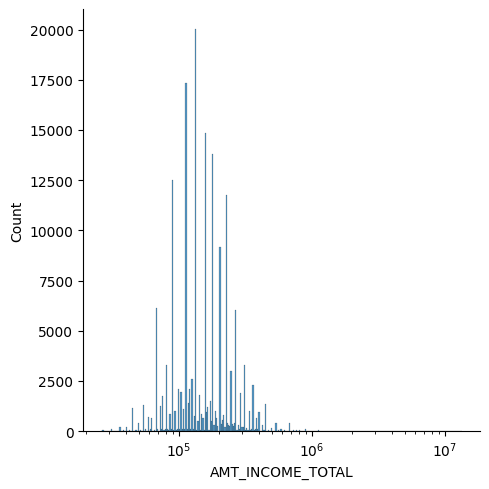

In [18]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [19]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but AMT_INCOME_TOTAL consists of only 1641 different values. Let's check the top 10 values specifically.

In [20]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

,count
AMT_INCOME_TOTAL,
135000.0,19969
112500.0,17320
157500.0,14772
180000.0,13791
90000.0,12481
225000.0,11573
202500.0,9128
67500.0,6130
270000.0,6006


It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE

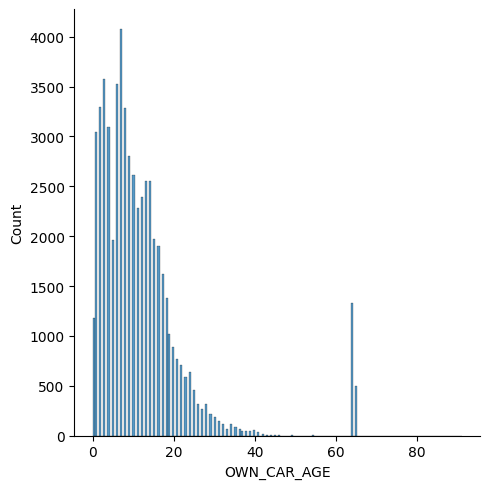

In [21]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and feature creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [22]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [23]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,4991,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,30898,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,1185,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,30898,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,37943,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


### EXT_SOURCE_* columns
Fill missing values in `EXT_SOURCE_1`, `EXT_SOURCE_2` and `EXT_SOURCE_3`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [24]:
# Complete missing values of EXT_SOURCE_* with the average
train["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
test["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
train["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)
test["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)

### CNT_FAM_MEMBERS column
We also fill missing values in `CNT_FAM_MEMBERS` with the mean.

In [25]:
train["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)
test["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)

### AMT_REQ_CREDIT_BUREAU_* columns
Replace `NaN` in `AMT_REQ_CREDIT_BUREAU_*` with **0** in both `train` and `test`.
These columns are **counts** of bureau inquiries, so `0` naturally means “no inquiries.”
This avoids relying on training-set statistics (no leakage) and keeps schemas consistent.

In [26]:
train["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)

train.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [27]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values.
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [28]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

array([nan,  0.,  2.,  1.,  3.,  4.,  5.])

In [29]:
# Apply One Hot Encodiing to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,0.0,0.0,0.0,0,False,False,False,False,False,False
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,0.0,0.0,1.0,0,False,False,False,False,False,False
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,0.0,0.0,0.0,0,False,False,False,False,False,False
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,0.0,0.0,0.0,0,False,False,False,False,False,False
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,0.0,0.0,4.0,1,False,False,False,False,False,False


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [30]:
# Loading libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 5.2 Preparing the Data
Split the data into features and the target using only numeric columns that exist in both train and test.
Since the target variable is TARGET, the remaining numeric columns become the explanatory variables.
This prevents errors from string/categorical values (e.g., "F") and guarantees the same feature schema for train and test.

In [31]:
# Extract numeric (int/float) columns only and align to the columns common to train and test
num_cols_train = train.drop(columns=['TARGET']).select_dtypes(include=['number']).columns
num_cols_test  = test.select_dtypes(include=['number']).columns
num_cols = num_cols_train.intersection(num_cols_test)

# Build arrays using numeric columns only (ensure the same column order for train/test)
X = train[num_cols].values
y = train['TARGET'].values
X_test = test[num_cols].values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [32]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [33]:
# Split the original data into the training data and the evaluatioin data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

Let's create models with logistic regression and random forest.

In [34]:
# LogisticRegression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

Train Score: 0.7259439217894387
Valid Score: 0.7253683473885177


In [35]:
# RandomForest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

Train Score: 0.8256570950645729
Valid Score: 0.7300922298203877


In [69]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

lgb = LGBMClassifier(
    objective="binary",
    eval_metric="auc",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=1.0,

    reg_alpha=1.0,
    reg_lambda=10.0,

    random_state=42,
    n_jobs=-1,
    verbosity=-1
    )

lgb.fit(X_train,
        y_train,
        eval_set=[(X_train, y_train), (X_valid, y_valid)],
        eval_metric="auc",
        callbacks=[
            early_stopping(
                stopping_rounds=11,
                first_metric_only=True,
            ),
            log_evaluation(period=100),
        ],
        )

lgb_train_pred = lgb.predict_proba(X_train)[:, 1]
lgb_valid_pred = lgb.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lgb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lgb_valid_pred)}")

Training until validation scores don't improve for 11 rounds
[100]	training's auc: 0.770518	training's binary_logloss: 0.242964	valid_1's auc: 0.740226	valid_1's binary_logloss: 0.251395
Early stopping, best iteration is:
[178]	training's auc: 0.790727	training's binary_logloss: 0.236727	valid_1's auc: 0.742693	valid_1's binary_logloss: 0.250659
Evaluated only: auc
Train Score: 0.7907133660309944
Valid Score: 0.742692880056892


In [58]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

gb_train_pred = gb.predict_proba(X_train)[:, 1]
gb_valid_pred = gb.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, gb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, gb_valid_pred)}")

Train Score: 0.7515394714886687
Valid Score: 0.7395021894639985


In [70]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",

    n_estimators=3000,
    learning_rate=0.05,
    early_stopping_rounds=100,

    max_depth=4,
    min_child_weight=20,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=5.0,

    tree_method="hist",
    n_jobs=-1,
    random_state=0
    )

xgb.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_valid, y_valid)], verbose=100)

xgb_train_pred = xgb.predict_proba(X_train)[:, 1]
xgb_valid_pred = xgb.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, xgb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, xgb_valid_pred)}")

[0]	validation_0-auc:0.69626	validation_1-auc:0.69394
[100]	validation_0-auc:0.74967	validation_1-auc:0.73691
[200]	validation_0-auc:0.76248	validation_1-auc:0.74157
[300]	validation_0-auc:0.77201	validation_1-auc:0.74399
[400]	validation_0-auc:0.78074	validation_1-auc:0.74541
[500]	validation_0-auc:0.78852	validation_1-auc:0.74612
[600]	validation_0-auc:0.79463	validation_1-auc:0.74645
[700]	validation_0-auc:0.80072	validation_1-auc:0.74657
[799]	validation_0-auc:0.80611	validation_1-auc:0.74600
Train Score: 0.8006640512102925
Valid Score: 0.7465952518114757


We find that random forest results with higher validation score.

### 5.4 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [72]:
train_pred = (lgb_train_pred + xgb_train_pred) / 2
valid_pred = (lgb_valid_pred + xgb_valid_pred) / 2

print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

Train Score: 0.7973222584794636
Valid Score: 0.7459349337449535


This time, we are able to improve the validation score using ensembling.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was the ensembling model. Therefore, we will use this model to make the final prediction.

In [86]:
# Make a prediction for the test data using ensemble learning
# pred = 0.5 * xgb.predict_proba(X_test_std)[:, 1]

In [91]:
pred = lgb_new.predict_proba(X_test_new)[:, 1]

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [89]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.031874
1,171203,0.193092
2,171204,0.157808
3,171205,0.101456
4,171206,0.176967
...,...,...
61495,232697,0.190830
61496,232698,0.034592
61497,232699,0.043485
61498,232700,0.175243


In [90]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

### Wrap-Up

That's all for the Home Credit Default Risk tutorial!

- Baseline validation AUC: **{0.732448}**  

### **[Next Steps]**
> * Are our missing-value strategies correct, or do alternatives (median/KNN) reduce leakage and improve CV?
> * How can we add the features we left out in this tutorial? What preprocessing is needed?
> * Do alternative model families (LightGBM/XGBoost/CatBoost) outperform under the same CV protocol?
> * Are key hyperparameters well tuned?